# 02 · Comparativa RNN simple vs LSTM vs GRU

Este notebook **no entrena nada**: carga los resultados guardados en `reports/results/` por el
pipeline (`tune` → `evaluate` → `timing` → `summarize`, ejecutado en la GPU) y los analiza.
Todas las métricas son fuera de muestra, en $/barril, sobre los mismos orígenes de previsión del
periodo de test (desde el 1-1-2022) para las tres redes y el modelo ingenuo.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

from oilcast.config import load_config
from oilcast.evaluation.report import comparison_table, stability_table, year_table
from oilcast.models.recurrent import ARCH_LABELS
from oilcast.paths import get_paths
from oilcast.training.tune import tuning_summary
from oilcast.utils import read_json

cfg = load_config()
paths = get_paths(cfg)
archs, horizons = cfg["architectures"], cfg["targets"]["horizons"]
comp = pd.read_csv(paths.results / "comparison.csv")
by_year = pd.read_csv(paths.results / "metrics_by_year.csv")
timing = pd.read_csv(paths.results / "timing.csv")
selection = read_json(paths.results / "selection.json")
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3})

## 1. Diseño experimental

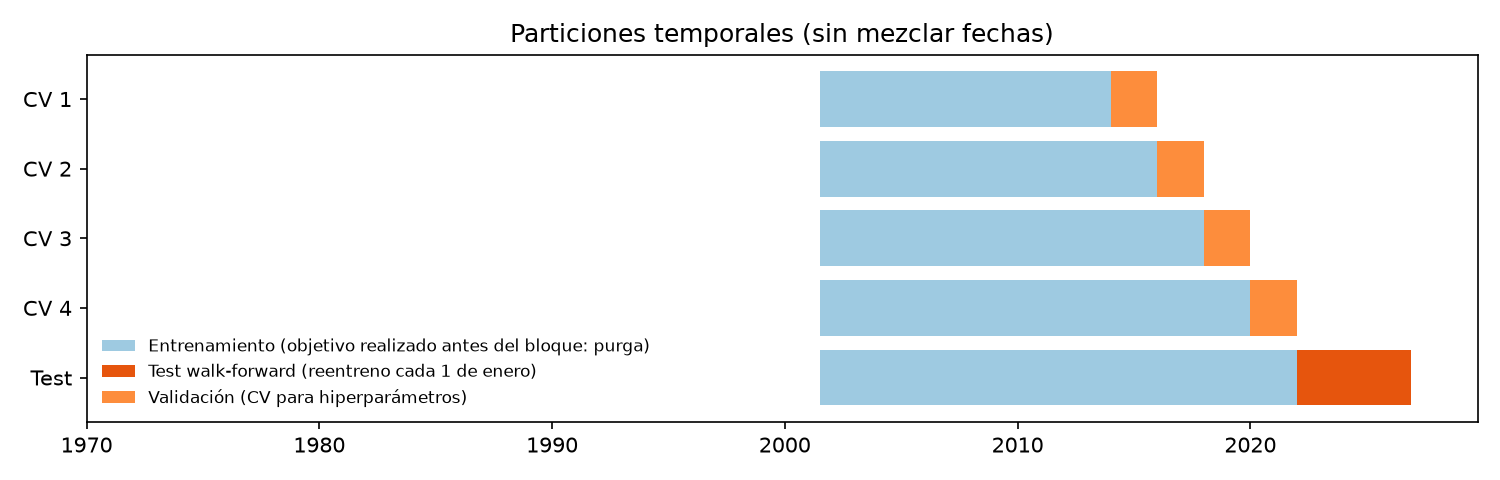

In [2]:
display(Image(paths.figures / "particiones.png"))

- **CV de hiperparámetros**: 4 bloques de validación de 2 años; para cada bloque se entrena solo
  con orígenes cuyo objetivo (precio a h días) ya se conoce antes de que empiece el bloque
  (*purga*). Optuna TPE, 80 trials por red y horizonte, misma semilla y mismo espacio
  (16-256 neuronas, 1-3 capas).
- **Sin deriva**: las redes aprenden desviaciones respecto a la media del entrenamiento, para que
  no proyecten al futuro la subida de 2001-2013.
- **Test**: reentreno cada 1 de enero (2022…2026) con todo lo realizado antes, hiperparámetros y
  nº de épocas fijados en la CV (sin *early stopping* sobre test), 5 semillas.
- **Recalibración del centro**: la mediana se encoge hacia el ingenuo con un factor en [0, 1]
  estimado con los errores ya conocidos en cada fecha.
- **Intervalos**: cuantiles 10-90 % de la red + calibración conformal con errores ya realizados
  antes de cada previsión.

Esta configuración es la adoptada tras dos rondas de experimentos (ver
`docs/registro-experimentos.md` y `docs/experimento-ronda2.md`); las variantes se resumen en
`reports/experiments/seleccion.csv`.

## 2. Hiperparámetros elegidos y pérdida de validación

In [3]:
tun = tuning_summary(paths, archs, horizons)
folds = {
    f"{a}_h{h}": read_json(paths.tuning_dir(a, h) / "best.json") for a in archs for h in horizons
}
tun.assign(
    pinball_por_fold=[
        np.round(folds[f"{r.arch}_h{r.horizon}"]["fold_losses"], 3).tolist()
        for r in tun.itertuples()
    ]
).round(4)

,arch,horizon,cv_pinball,final_epochs,n_trials,n_pruned,hidden_size,num_layers,dropout,lr,weight_decay,batch_size,pinball_por_fold
0,rnn,5,0.2464,25,80,31,64,1,0.4978,0.0006,0.0000,128,"[0.2, 0.221, 0.177, 0.387]"
1,rnn,63,0.2736,7,80,30,64,3,0.4192,0.0021,0.0000,256,"[0.331, 0.143, 0.195, 0.425]"
2,rnn,252,0.2519,9,80,43,256,1,0.3817,0.0017,0.0005,128,"[0.374, 0.12, 0.262, 0.252]"
3,lstm,5,0.2450,3,80,40,256,3,0.0859,0.0009,0.0005,128,"[0.195, 0.218, 0.18, 0.387]"
4,lstm,63,0.2885,4,80,20,64,3,0.3206,0.0021,0.0001,256,"[0.351, 0.149, 0.182, 0.473]"
5,lstm,252,0.2692,22,80,48,64,3,0.1095,0.0026,0.0033,128,"[0.454, 0.102, 0.254, 0.267]"
6,gru,5,0.2459,2,80,35,256,3,0.4684,0.0029,0.0097,128,"[0.199, 0.22, 0.179, 0.385]"
7,gru,63,0.2954,37,80,28,32,2,0.4606,0.0001,0.0000,64,"[0.4, 0.154, 0.182, 0.444]"
8,gru,252,0.2720,4,80,47,256,3,0.2460,0.0019,0.0076,64,"[0.508, 0.099, 0.271, 0.209]"


## 3. Tabla comparativa en test

In [4]:
display(Markdown(comparison_table(comp, horizons, archs)))

| Horizonte | Modelo | MAE ($) | RMSE ($) | R² | Mejora MAE vs ingenuo | Mejora RMSE vs ingenuo | p-valor DM | Acierto direccional | Cobertura IC80 | Anchura IC80 ($) | Winkler IC80 | Parámetros | Tiempo entren. (s) |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Corto (5 d) | Ingenuo | 3.99 | 5.74 | 0.875 | — | — | — | — | 76.1 % | 10.61 | 19.93 | — | — |
| Corto (5 d) | RNN simple | 3.96 | 5.71 | 0.876 | +0.6 % | +0.5 % | 0.148 | 53.3 % | 78.1 % | 10.80 | 19.09 | 5959 | 0.8 |
| Corto (5 d) | LSTM | 3.99 | 5.74 | 0.875 | +0.0 % | +0.0 % | — | — | 74.7 % | 10.54 | 19.00 | 1339143 | 0.6 |
| Corto (5 d) | GRU | 3.99 | 5.74 | 0.875 | +0.0 % | +0.0 % | 0.445 | 50.7 % | 78.8 % | 11.41 | 19.16 | 1004807 | 0.4 |
| Medio (63 d) | Ingenuo | 11.94 | 17.44 | -0.207 | — | — | — | — | 84.5 % | 38.45 | 65.21 | — | — |
| Medio (63 d) | RNN simple | 11.50 | 17.13 | -0.165 | +3.7 % | +1.7 % | 0.105 | 59.2 % | 87.6 % | 49.05 | 75.11 | 22599 | 0.2 |
| Medio (63 d) | LSTM | 11.57 | 17.33 | -0.192 | +3.2 % | +0.6 % | 0.855 | 60.0 % | 84.2 % | 44.11 | 72.06 | 89031 | 0.2 |
| Medio (63 d) | GRU | 11.26 | 16.98 | -0.143 | +5.7 % | +2.6 % | 0.427 | 65.3 % | 87.8 % | 47.99 | 74.32 | 11751 | 3.2 |
| Largo (252 d) | Ingenuo | 16.50 | 22.53 | -1.466 | — | — | — | — | 93.4 % | 90.15 | 97.57 | — | — |
| Largo (252 d) | RNN simple | 15.00 | 17.84 | -0.548 | +9.1 % | +20.8 % | 0.413 | 57.0 % | 99.6 % | 88.38 | 88.55 | 68117 | 0.3 |
| Largo (252 d) | LSTM | 14.85 | 17.86 | -0.550 | +10.0 % | +20.7 % | 0.396 | 53.6 % | 99.6 % | 89.95 | 90.17 | 84181 | 1.1 |
| Largo (252 d) | GRU | 15.55 | 19.29 | -0.809 | +5.7 % | +14.4 % | 0.526 | 61.1 % | 98.9 % | 90.49 | 91.38 | 990229 | 1.1 |

*Mejora* = 1 − error del modelo / error del ingenuo. *p-valor DM*: Diebold-Mariano con varianza
HAC (h−1 retardos) sobre el error cuadrático. Cobertura y anchura del intervalo del 80 % tras la
calibración conformal (el ingenuo usa los cuantiles históricos de las variaciones a h días).

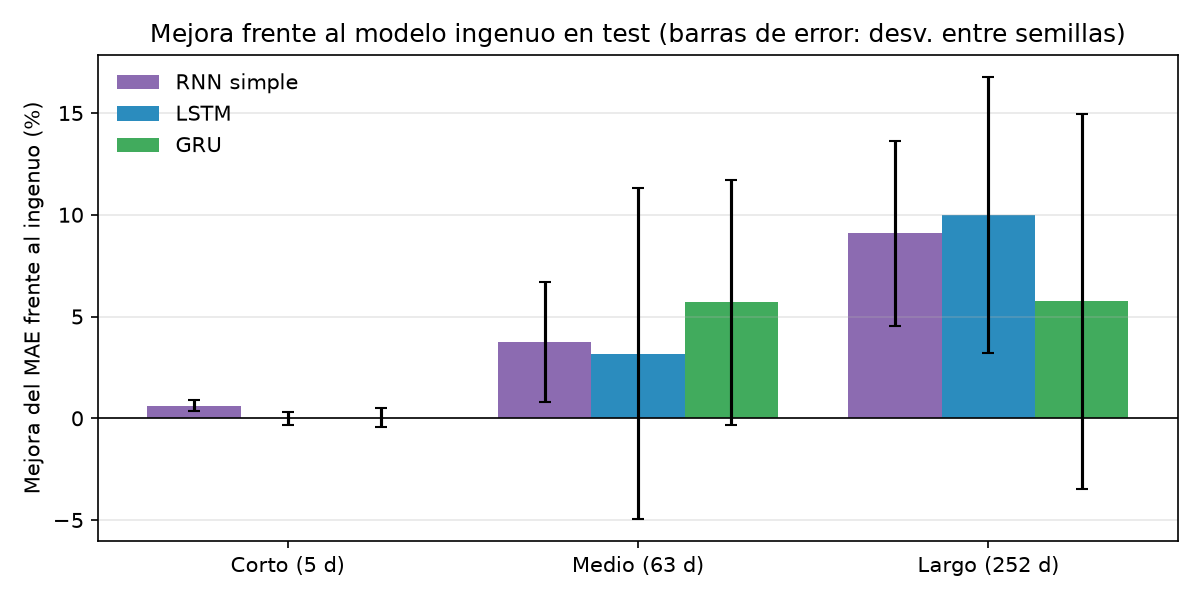

In [5]:
display(Image(paths.figures / "mejora_vs_ingenuo.png"))

## 4. Estabilidad entre semillas y calibración del intervalo

In [6]:
display(Markdown(stability_table(comp, horizons, archs)))

| Horizonte | Modelo | MAE ensemble | MAE por semilla (media ± desv.) | Mejora MAE por semilla (desv.) | Cobertura IC80 sin calibrar | MSE |
|---|---|---|---|---|---|---|
| Corto (5 d) | RNN simple | 3.96 | 3.94 ± 0.01 | 0.3 % | 73.4 % | 32.6 |
| Corto (5 d) | LSTM | 3.99 | 3.99 ± 0.01 | 0.3 % | 73.8 % | 32.9 |
| Corto (5 d) | GRU | 3.99 | 3.99 ± 0.02 | 0.5 % | 77.2 % | 32.9 |
| Medio (63 d) | RNN simple | 11.50 | 11.52 ± 0.35 | 2.9 % | 77.9 % | 293.6 |
| Medio (63 d) | LSTM | 11.57 | 13.63 ± 0.97 | 8.1 % | 71.0 % | 300.3 |
| Medio (63 d) | GRU | 11.26 | 14.10 ± 0.72 | 6.0 % | 71.6 % | 288.2 |
| Largo (252 d) | RNN simple | 15.00 | 15.19 ± 0.75 | 4.5 % | 98.0 % | 318.4 |
| Largo (252 d) | LSTM | 14.85 | 15.19 ± 1.12 | 6.8 % | 96.6 % | 319.0 |
| Largo (252 d) | GRU | 15.55 | 15.92 ± 1.52 | 9.2 % | 94.0 % | 372.3 |


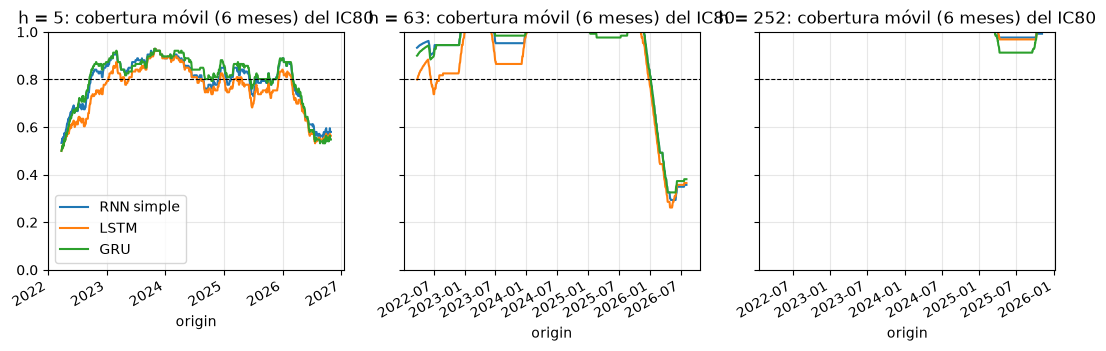

In [7]:
fig, axes = plt.subplots(1, len(horizons), figsize=(13, 3.5), sharey=True)
for ax, h in zip(axes, horizons, strict=True):
    for a in archs:
        e = pd.read_csv(
            paths.results / "predictions" / f"{a}_h{h}_ensemble.csv", parse_dates=["origin"]
        )
        t = e[e["phase"] == "test"].set_index("origin")
        inside = ((t["y"] >= t["lo80"]) & (t["y"] <= t["hi80"])).astype(float)
        inside.rolling(126, min_periods=60).mean().plot(ax=ax, label=ARCH_LABELS[a])
    ax.axhline(0.8, color="black", ls="--", lw=0.8)
    ax.set_title(f"h = {h}: cobertura móvil (6 meses) del IC80")
axes[0].legend()
axes[0].set_ylim(0, 1);

## 5. ¿Cuándo aporta valor? Resultados por año

In [8]:
display(Markdown(year_table(by_year, horizons, archs)))

| Horizonte | Modelo | 2022 | 2023 | 2024 | 2025 | 2026 |
|---|---|---|---|---|---|---|
| Corto (5 d) | RNN simple | +1.0 % | +0.4 % | +1.5 % | +0.7 % | +0.0 % |
| Corto (5 d) | LSTM | +0.0 % | +0.0 % | +0.0 % | +0.0 % | +0.0 % |
| Corto (5 d) | GRU | +0.1 % | -0.0 % | +0.1 % | -0.0 % | +0.0 % |
| Corto (5 d) | MAE ingenuo ($) | 5.35 | 3.00 | 2.36 | 2.39 | 7.45 |
| Medio (63 d) | RNN simple | +8.1 % | +3.0 % | +9.1 % | -0.9 % | +1.9 % |
| Medio (63 d) | LSTM | -5.7 % | -1.5 % | +30.0 % | +4.6 % | +3.7 % |
| Medio (63 d) | GRU | +21.9 % | -13.8 % | +7.8 % | +5.9 % | +2.9 % |
| Medio (63 d) | MAE ingenuo ($) | 12.94 | 8.62 | 4.82 | 9.07 | 32.75 |
| Largo (252 d) | RNN simple | +45.1 % | -10.5 % | -122.2 % | +47.4 % | — |
| Largo (252 d) | LSTM | +42.4 % | -19.7 % | -96.9 % | +42.9 % | — |
| Largo (252 d) | GRU | +38.1 % | -31.4 % | -95.9 % | +38.6 % | — |
| Largo (252 d) | MAE ingenuo ($) | 19.32 | 7.61 | 11.43 | 29.64 | — |


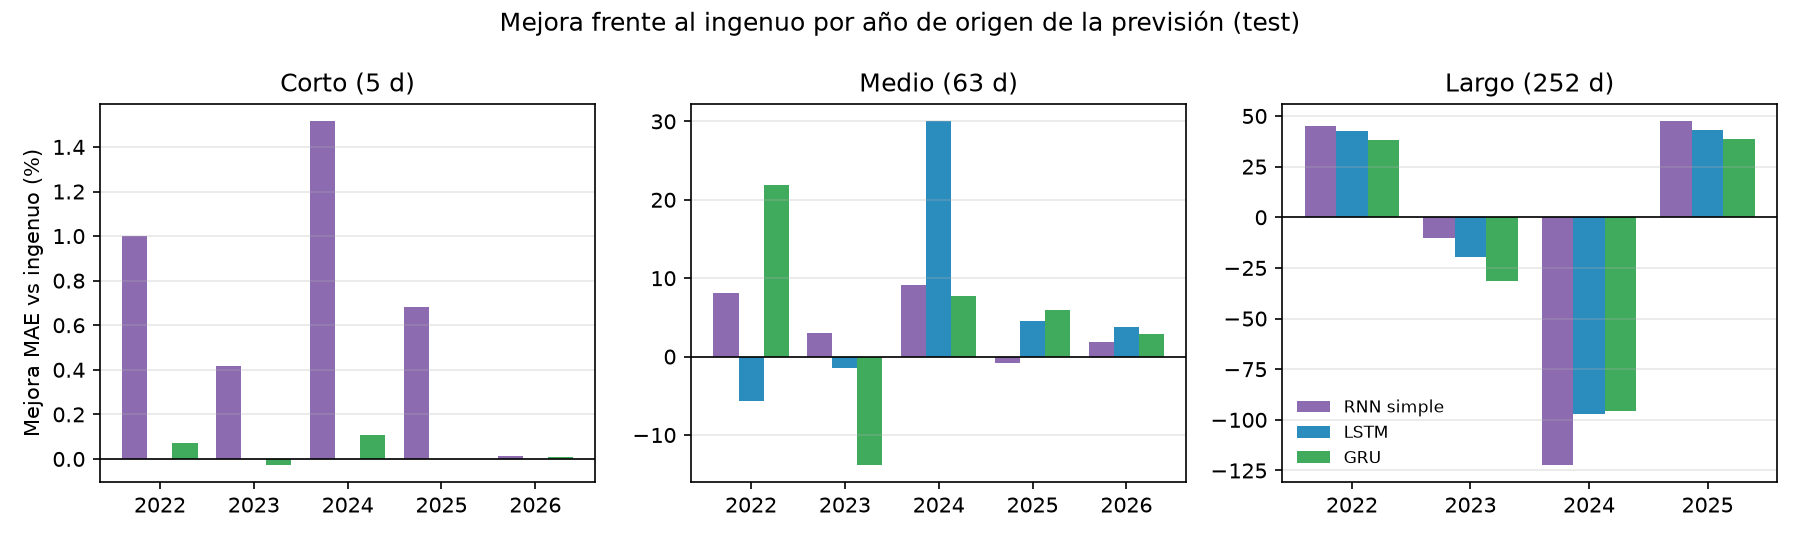

In [9]:
display(Image(paths.figures / "mejora_por_anio.png"))

## 6. ¿Qué predice realmente la red?

La mediana prevista por la red frente a la variación realizada. Una nube centrada cerca de 0 en
el eje vertical indica que la red ha aprendido que la mejor apuesta central es «casi sin cambio»
(y pone su valor en el rango); una pendiente clara indicaría capacidad direccional.

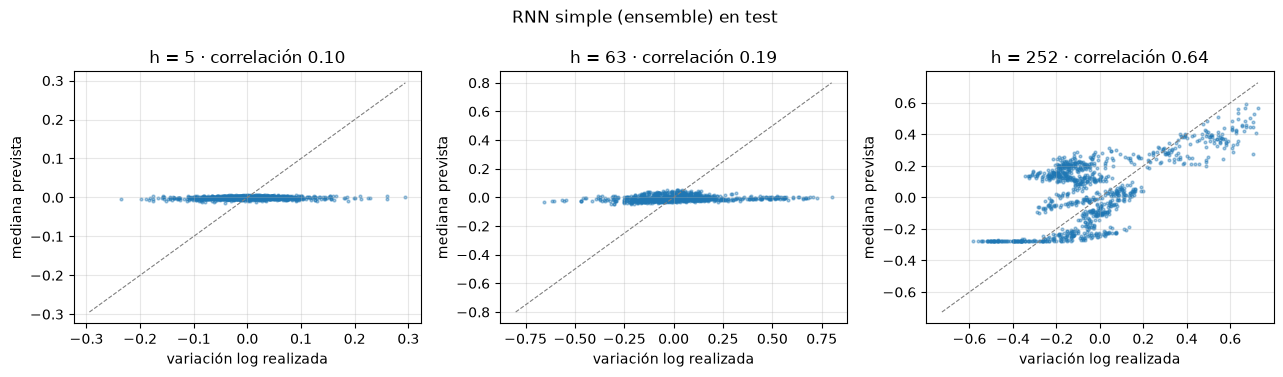

In [10]:
chosen = selection["chosen"]
fig, axes = plt.subplots(1, len(horizons), figsize=(13, 3.8))
for ax, h in zip(axes, horizons, strict=True):
    e = pd.read_csv(paths.results / "predictions" / f"{chosen}_h{h}_ensemble.csv")
    t = e[e["phase"] == "test"]
    ax.scatter(t["y"], t["q50"], s=4, alpha=0.4)
    lim = np.abs(t["y"]).max()
    ax.plot([-lim, lim], [-lim, lim], color="grey", lw=0.8, ls="--")
    rho = np.corrcoef(t["y"], t["q50"])[0, 1]
    ax.set_title(f"h = {h} · correlación {rho:.2f}")
    ax.set_xlabel("variación log realizada")
    ax.set_ylabel("mediana prevista")
fig.suptitle(f"{ARCH_LABELS[chosen]} (ensemble) en test")
fig.tight_layout();

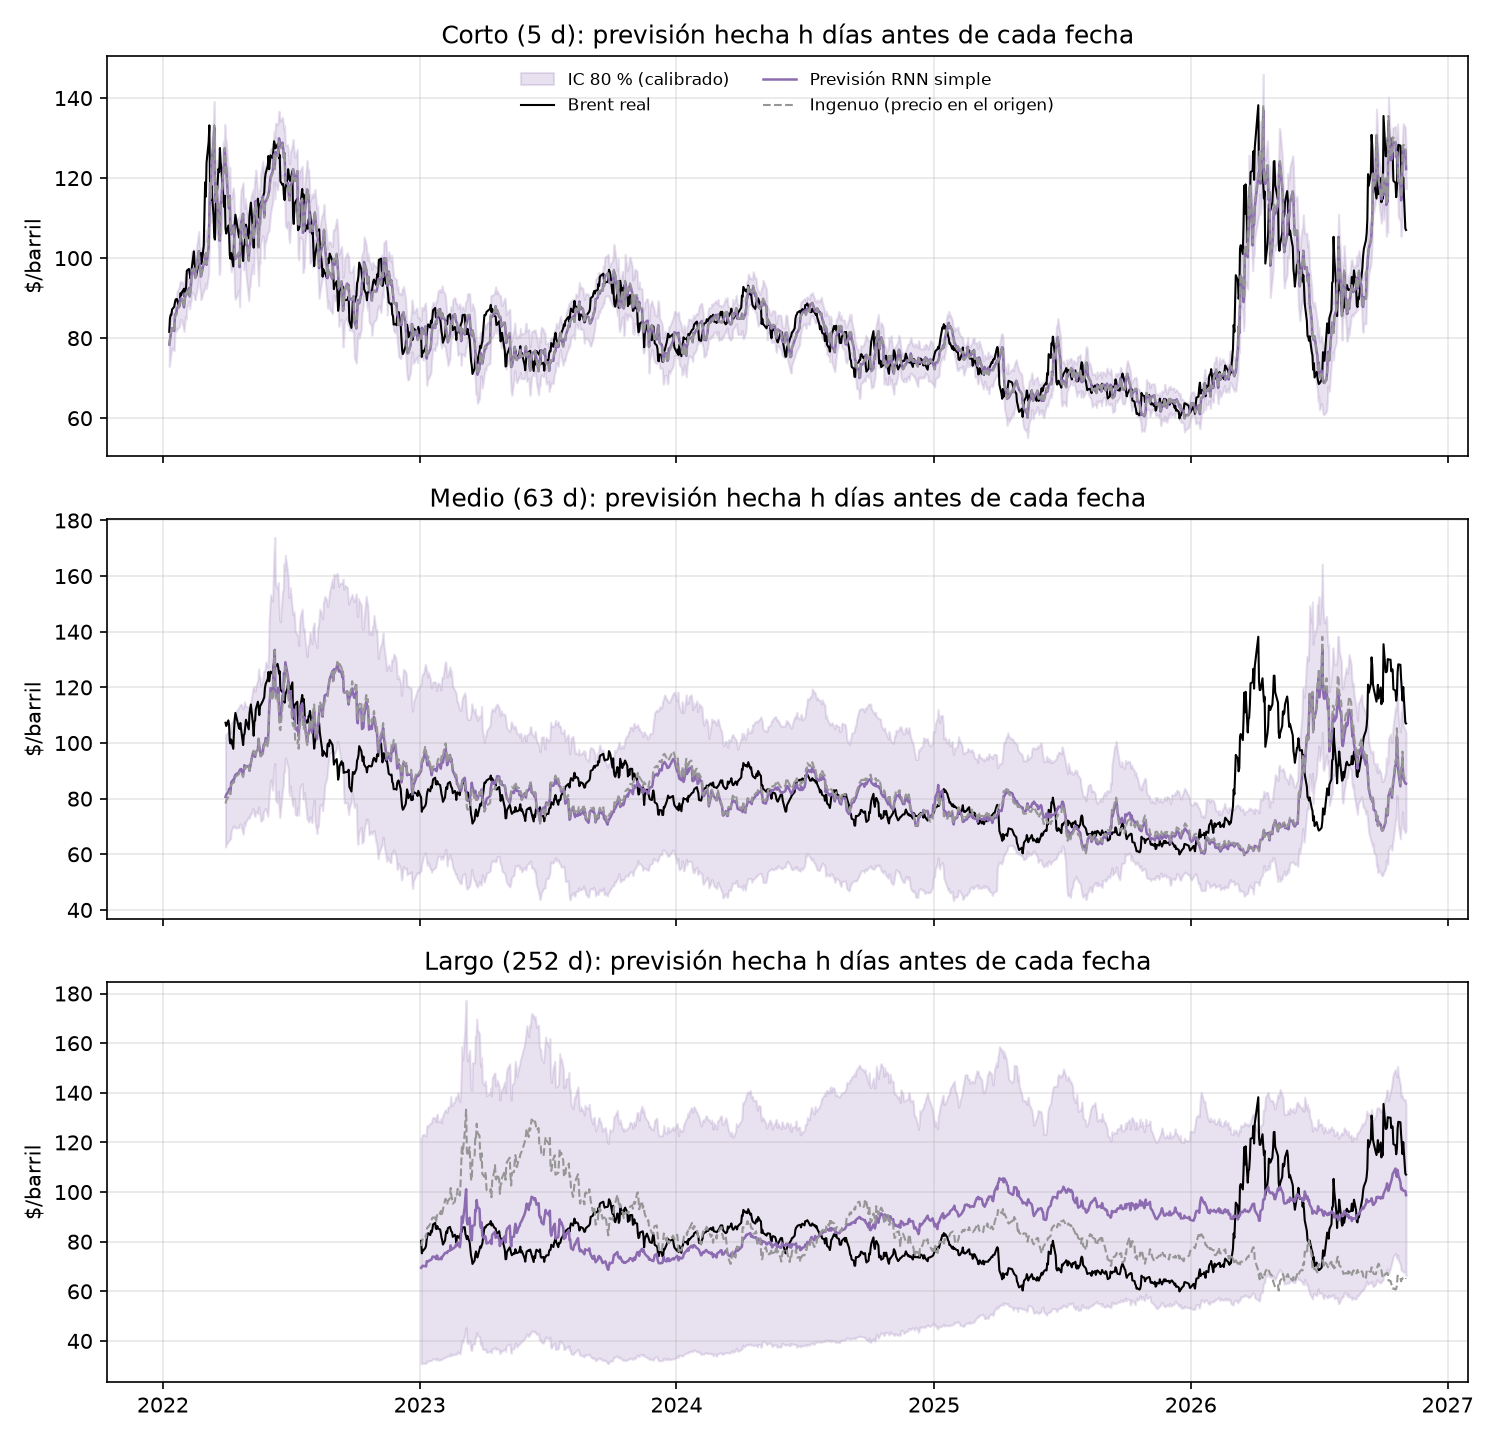

In [11]:
display(Image(paths.figures / "predicciones_test.png"))

## 7. Coste computacional

In [12]:
timing.pivot_table(
    index="arch", columns="horizon", values=["train_seconds", "n_params", "epochs"]
).round(1)

epochs               n_params                    train_seconds       \
horizon    5     63    252        5        63        252           5    63    
arch                                                                          
gru        2.0  37.0   4.0  1004807.0  11751.0  990229.0           0.4  3.2   
lstm       3.0   4.0  22.0  1339143.0  89031.0   84181.0           0.6  0.2   
rnn       25.0   7.0   9.0     5959.0  22599.0   68117.0           0.8  0.2   

              
horizon  252  
arch          
gru      1.1  
lstm     1.1  
rnn      0.3

## 8. Elección del modelo y conclusiones

In [13]:
print(selection["rule"])
display(pd.DataFrame(selection["scores"]).round(4))
# variantes que ganan a la RNN en algún plazo del test y por qué no se usan
pd.DataFrame(selection.get("alternatives", []))

La aplicación usa la RNN simple en los tres plazos (propuesta B): 20 variables diarias a 1 semana y 3 meses, y la relación oro/crudo a 1 año. En el test es la mejor de las tres redes a 1 semana y en la media de los tres plazos, la que menos varía entre semillas y la que tiene menos parámetros. La combinación se eligió después de ver el test 2022-2026: antes de 2022 mejoraba al ingenuo un 3,7 % de media, frente al 5,3 % de la LSTM que había elegido la regla de la ronda 4. La ronda 5 probó variantes con una regla fijada antes de entrenar y ninguna superó a B en todos los periodos anteriores a 2022.


,arch,mean_rel_mae,mean_rel_seed_std,mean_params,mean_coverage80
0,rnn,0.9552,0.0278,32225.0000,0.8842
1,lstm,0.9562,0.0542,504118.3333,0.8617
2,gru,0.9617,0.0555,668929.0000,0.8848


,horizon,name,test,development,reason
0,5,GRU de la primera versión de la app,"+1,6 % (B +0,6 %)",—,Es otra arquitectura y pierde en los otros pla...
1,5,RNN con el movimiento de los futuros tras la v...,"+0,9 % (B +0,6 %)","−0,2 % (B −0,2 %)",Antes de 2022 empataba con B. En el test la di...
2,63,"Media de RNN, LSTM y GRU (ronda 5)","+7,1 % (B +3,7 %)","−1,5 % (B −1,6 %)",Mezcla tres arquitecturas y antes de 2022 empa...
3,63,GRU con las mismas variables,"+5,7 % (B +3,7 %)","−1,2 % (B −1,6 %)",Es otra arquitectura. A 1 semana no mejora al ...
4,252,LSTM con la relación oro/crudo,"+10,0 % (B +9,1 %)","+12,9 % (B +13,0 %)",Es otra arquitectura. A 1 semana no se aparta ...
5,252,RNN con 20 semillas en lugar de 5 (ronda 5),"+11,1 % (B +9,1 %)","+14,7 % (B +13,0 %)","En 2008-2013 quedaba 0,3 puntos por debajo de ..."


### Conclusiones

**Modelo elegido: RNN simple (propuesta B).** A 5 y 63 sesiones es la red W1, elegida antes de
ver el test con la regla de `docs/experimento-ronda2.md`. A 252 sesiones solo recibe la relación
oro/crudo (barriles por onza frente a su media de 3 años), con un atajo lineal
(`docs/experimento-ronda4.md`).

**Por qué la RNN simple:**

- **Precisión**: en el test es la mejor de las tres redes a 5 sesiones (+0,6 %, frente a 0,0 %
  de la LSTM y la GRU) y en la media de los tres plazos (MAE 0,955 veces el del ingenuo, frente
  a 0,956 de la LSTM y 0,962 de la GRU).
- **Estabilidad**: la desviación del MAE entre semillas es del 2,8 %, frente al 5,4 % y el 5,6 %.
- **Coste computacional**: 32.000 parámetros de media, frente a 504.000 y 669.000. Las tres
  redes se entrenan en segundos en GPU.

**Esta combinación se eligió después de ver el test.** La regla de la ronda 4, fijada de
antemano, eligió una LSTM: mejor antes de 2022 (+5,3 % frente a +3,7 %) y peor en el test
(+2,6 % frente a +4,5 %).

**Dónde aporta valor frente al ingenuo y dónde no** (RNN simple, test 2022-2026):

- **Corto plazo (5 días)**: +0,6 % de MAE, positiva en los 5 años y con las 5 semillas, pero
  solo 2,5 céntimos por barril. No significativa en error cuadrático (p = 0,15). Antes de 2022
  no ganaba (−0,2 %).
- **Medio plazo (63 días)**: +3,7 % de MAE, positiva en 4 de 5 años y con las 5 semillas;
  intervalo bootstrap del 90 % entre +1,1 % y +6,7 % (p = 0,015 en error absoluto). Antes de
  2022 perdía un 1,6 %. El intervalo del 80 % es más ancho que el del ingenuo.
- **Largo plazo (252 días)**: +9,1 % de MAE y +20,8 % de RMSE, pero **depende de pocos
  episodios**: gana en las previsiones de 2022 y 2025 (que acertaron la subida de 2026 por la
  guerra con Irán) y pierde en 2023 y 2024. Sin las de 2025 pierde un 16 %, y en el test no se
  distingue del azar (bootstrap entre −63 % y +46 %). Su respaldo está antes de 2022: +19 % en
  2008-2013 y +8 % en 2014-2021.

**Alternativas que ganan en el test** (tabla anterior). A 5 sesiones, la RNN con el
movimiento de los futuros obtiene +0,9 %. A 63 sesiones, la media de las tres redes llega a
+7,1 % y la GRU sola a +5,7 %. A 252 sesiones, la LSTM obtiene +10,0 % y la RNN con 20
semillas, +11,1 %. Ninguna gana a B a la vez en los tres plazos, en el test y en todos los
periodos anteriores a 2022, y la media mezcla arquitecturas. Cambiar el modelo por una de ellas
sería ajustarlo a un periodo que ya se usó para elegir B
(`reports/experiments/ronda5/resultado.md`).

Es el resultado esperable para el crudo: con información de mercado pasada, el precio se
comporta casi como un paseo aleatorio. La aplicación muestra siempre el intervalo, dice en cada
horizonte si el modelo mejoró o no al «precio no cambia» y explica en qué se basa la previsión
anual y qué la puede invalidar. Verificación completa en
`reports/experiments/propuesta_b/resultado.md`.

**Nota sobre la calibración**: el intervalo conformal usa todos los errores ya realizados
(ventana expansiva); con una ventana corta, a 252 días equivaldría a muy pocos años
independientes y daría intervalos degenerados. A 252 días el intervalo es prudente en exceso
(cubre el 99,6 % de los casos).